# 01 – Exploratory data analysis: `player_season`

**Question for the project:** which players produce more on the field than their contracts pay for?

This notebook takes a first look at the modeling table built by the SQL in `sql/` (run `python -m src.features`).
One row = one player in one regular season (2019–2025), QB/RB/WR/TE, with at least 200 offensive snaps,
joined to the contract in force that season.

We look at:
1. What's in the table, and whether anything is missing
2. How **EPA per play** is distributed at each position
3. How **pay (APY as % of cap)** relates to **production (total EPA)** at each position

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

DB_PATH = Path.cwd().parent / "data" / "nfl.duckdb"   # notebook runs from notebooks/
POSITIONS = ["QB", "RB", "WR", "TE"]

with duckdb.connect(str(DB_PATH), read_only=True) as con:
    ps = con.sql("SELECT * FROM player_season").df()

print(f"{len(ps):,} player-seasons, {ps['gsis_id'].nunique():,} distinct players, {ps.shape[1]} columns")

2,402 player-seasons, 817 distinct players, 29 columns


In [2]:
# Chart style: recessive axes and grid so the data marks carry the eye.
BLUE, ORANGE = "#2a78d6", "#eb6834"          # validated categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

## 1. What's in the table

In [3]:
# Player-seasons per position and season: the table should be balanced across years.
pd.crosstab(ps["position"], ps["season"], margins=True, margins_name="total").loc[POSITIONS + ["total"]]

season,2019,2020,2021,2022,2023,2024,2025,total
position,,,,,,,,
QB,41,42,44,48,49,47,46,317
RB,69,76,73,73,70,72,72,505
WR,138,146,147,138,147,142,145,1003
TE,79,80,84,82,80,86,86,577
total,327,344,348,341,346,347,349,2402


In [4]:
# Missing values per column. Expected gaps: cpoe (QBs only), yards_after_catch (players with no catches).
missing = ps.isna().sum()
missing[missing > 0].to_frame("n_missing")

,n_missing
receptions,262
cpoe,2085
air_yards,262
yards_after_catch,276
contract_type,375


In [5]:
# Summary statistics by position for the main features.
cols = ["offense_snaps", "snap_pct", "plays", "total_epa", "epa_per_play", "success_rate",
        "cpoe", "target_share", "air_yards_share", "age", "apy", "apy_cap_pct"]
summary = ps.groupby("position")[cols].agg(["mean", "median"]).loc[POSITIONS].round(3)
summary.T

position                     QB       RB       WR       TE
offense_snaps   mean    731.038  448.950  577.118  509.298
                median  777.000  413.000  560.000  478.000
snap_pct        mean      0.887    0.467    0.616    0.527
                median    0.942    0.461    0.646    0.508
plays           mean    435.659  177.038   70.202   43.348
                median  457.000  168.000   60.000   34.000
total_epa       mean     21.041   -7.173   16.764    9.290
                median    8.140   -6.579   12.615    5.470
epa_per_play    mean      0.018   -0.045    0.206    0.190
                median    0.021   -0.041    0.224    0.204
success_rate    mean      0.455    0.411    0.501    0.529
                median    0.459    0.406    0.500    0.529
cpoe            mean     -0.248      NaN      NaN      NaN
                median    0.240      NaN      NaN      NaN
target_share    mean      0.001    0.082    0.146    0.091
                median    0.000    0.078    0.139    0.074
air_yards_share mean      0.000    0.003    0.199    0.079
                median    0.000    0.002    0.180    0.062
age             mean     28.463   25.913   26.044   26.890
                median   27.280   25.511   25.640   26.448
apy             mean     17.460    3.386    5.589    3.825
                median    8.788    1.650    2.000    1.750
apy_cap_pct     mean      0.084    0.016    0.027    0.019
                median    0.042    0.008    0.010    0.009

In [6]:
# Share of player-seasons played on a rookie-scale contract.
ps.groupby("position")["is_rookie_contract"].mean().loc[POSITIONS].round(3).to_frame("pct_rookie_contract")

,pct_rookie_contract
position,
QB,0.341
RB,0.430
WR,0.416
TE,0.385


## 2. EPA per play by position

EPA per play = the player's total EPA divided by the plays credited to him
(QB dropbacks, designed rushes, targets). Each panel is one position; the dashed line is the median.

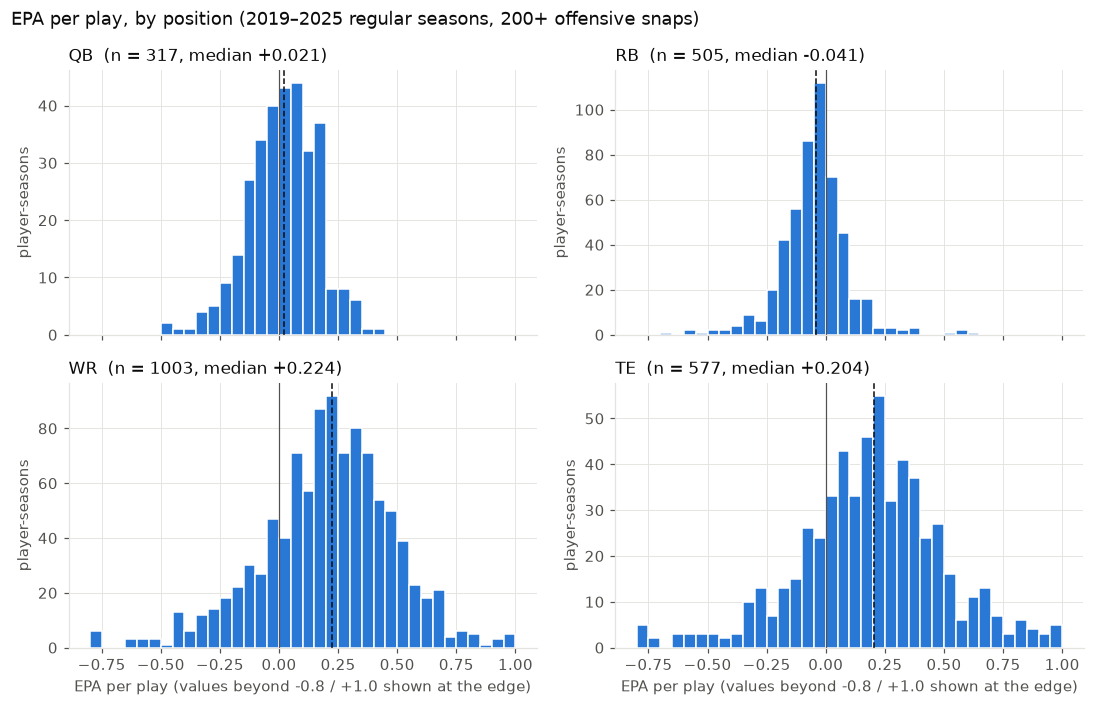

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
bins = [x / 20 for x in range(-16, 21)]   # -0.8 to 1.0 in steps of 0.05

for ax, pos in zip(axes.flat, POSITIONS):
    vals = ps.loc[ps["position"] == pos, "epa_per_play"]
    ax.hist(vals.clip(-0.8, 1.0), bins=bins, color=BLUE, edgecolor="white", linewidth=1)
    med = vals.median()
    ax.axvline(med, color=INK, linestyle="--", linewidth=1)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_title(f"{pos}  (n = {len(vals)}, median {med:+.3f})", loc="left", fontsize=11)
    ax.set_ylabel("player-seasons")

for ax in axes[1]:
    ax.set_xlabel("EPA per play (values beyond -0.8 / +1.0 shown at the edge)")
fig.suptitle("EPA per play, by position (2019–2025 regular seasons, 200+ offensive snaps)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
plt.show()

In [8]:
# The numbers behind the chart, plus how many plays a typical player-season has
# (fewer plays = a noisier EPA/play).
ps.groupby("position").agg(
    n=("epa_per_play", "size"),
    median_plays=("plays", "median"),
    p10=("epa_per_play", lambda s: s.quantile(0.10)),
    median=("epa_per_play", "median"),
    p90=("epa_per_play", lambda s: s.quantile(0.90)),
    std=("epa_per_play", "std"),
).loc[POSITIONS].round(3)

,n,median_plays,p10,median,p90,std
position,,,,,,
QB,317,457.0,-0.159,0.021,0.194,0.148
RB,505,168.0,-0.190,-0.041,0.093,0.141
WR,1003,60.0,-0.151,0.224,0.526,0.282
TE,577,34.0,-0.182,0.204,0.553,0.319


## 3. Pay vs production by position

x = APY as a % of the salary cap (the cost), y = total EPA in the season (the production).
Orange = rookie-scale contract, blue = every other contract. Each panel has its own y-axis
because QBs are involved in far more plays than anyone else.

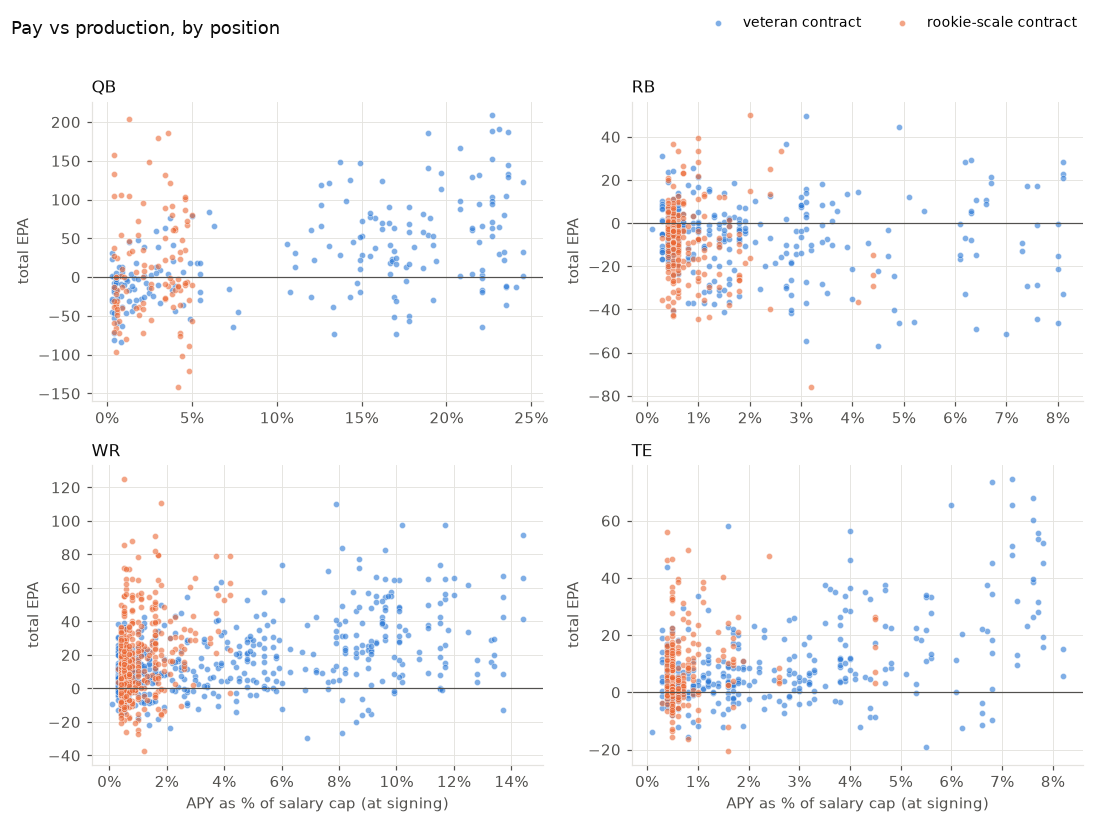

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))

for ax, pos in zip(axes.flat, POSITIONS):
    d = ps[ps["position"] == pos]
    for is_rookie, color, label in [(False, BLUE, "veteran contract"), (True, ORANGE, "rookie-scale contract")]:
        s = d[d["is_rookie_contract"] == is_rookie]
        ax.scatter(s["apy_cap_pct"], s["total_epa"], s=16, color=color, alpha=0.6,
                   edgecolors="white", linewidths=0.4, label=label)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_title(pos, loc="left", fontsize=11)
    ax.set_ylabel("total EPA")

for ax in axes[1]:
    ax.set_xlabel("APY as % of salary cap (at signing)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.99, 1.0))
fig.suptitle("Pay vs production, by position", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [10]:
# How strongly does pay track production? Spearman (rank) correlation between
# APY % of cap and total EPA, overall and split by contract type.
def spearman(d):
    return d["apy_cap_pct"].corr(d["total_epa"], method="spearman")

pd.DataFrame({
    "all": ps.groupby("position").apply(spearman, include_groups=False),
    "veteran only": ps[~ps["is_rookie_contract"]].groupby("position").apply(spearman, include_groups=False),
    "median cap % (rookie)": ps[ps["is_rookie_contract"]].groupby("position")["apy_cap_pct"].median(),
    "median cap % (veteran)": ps[~ps["is_rookie_contract"]].groupby("position")["apy_cap_pct"].median(),
}).loc[POSITIONS].round(3)

,all,veteran only,median cap % (rookie),median cap % (veteran)
position,,,,
QB,0.423,0.521,0.026,0.137
RB,-0.069,-0.050,0.006,0.014
WR,0.323,0.424,0.007,0.017
TE,0.257,0.391,0.005,0.017


In [11]:
# The most productive seasons on the cheapest deals: a preview of the "underpaid" question.
cheap_stars = (ps[ps["apy_cap_pct"] <= 0.02]
               .nlargest(10, "total_epa")
               [["player_name", "position", "season", "team", "total_epa", "epa_per_play", "apy", "apy_cap_pct", "is_rookie_contract"]])
cheap_stars.round(3)

,player_name,position,season,team,total_epa,epa_per_play,apy,apy_cap_pct,is_rookie_contract
222,Lamar Jackson,QB,2019,BAL,204.452,0.353,2.368,0.013,True
1900,Brock Purdy,QB,2023,SF,156.906,0.316,0.934,0.004,True
854,Dak Prescott,QB,2019,DAL,132.563,0.201,0.681,0.004,True
1438,Puka Nacua,WR,2025,LA,125.031,0.710,1.021,0.005,True
1377,CeeDee Lamb,WR,2023,DAL,110.855,0.568,3.503,0.018,True
766,Jalen Hurts,QB,2022,PHI,105.712,0.165,1.506,0.008,True
223,Lamar Jackson,QB,2020,BAL,105.251,0.190,2.368,0.013,True
1901,Brock Purdy,QB,2024,SF,105.153,0.194,0.934,0.004,True
1421,Jaxon Smith-Njigba,WR,2025,SEA,90.719,0.534,3.604,0.016,True
1572,George Pickens,WR,2025,DAL,87.690,0.640,1.688,0.008,True


## Observations

All numbers below come from the cells above.

1. **The table is balanced across seasons** (327–349 player-seasons each year) and every row has a contract.
   The only systematic gaps are expected: CPOE exists only for QBs, and receiving columns are empty for
   players who were never targeted.
2. **EPA per play isn't comparable across positions.** Medians: QB +0.021, RB −0.041, WR +0.224, TE +0.204.
   Receivers are only credited on targets (pass plays, which are worth more on average than runs), while RBs
   are mostly credited on runs, which are usually negative EPA. So players must be compared *within* their
   position: in Phase 3 the model needs position as a feature, or one model per position.
3. **Small samples are noisy.** A typical TE season has 34 plays credited to him and an EPA/play std of 0.319;
   a typical QB season has 457 plays and a std of 0.148. Clearing 200 snaps doesn't guarantee many *touches*,
   so a per-play rate from a small denominator should be treated cautiously (total EPA, or weighting by plays).
4. **Pay tracks production at QB, WR and TE, but barely at RB.** Spearman correlation between cap % and total
   EPA: QB 0.42, WR 0.32, TE 0.26, RB −0.07. Among veteran contracts only it rises to 0.52 / 0.42 / 0.39 / −0.05:
   rookie deals blur the link because their pay is fixed by draft slot, not performance.
5. **Rookie contracts are where the bargains are.** Median cap % on rookie deals is 0.5–2.6% vs 1.4–13.7% on
   veteran deals, and all ten most productive seasons on ≤2% of the cap were rookie contracts
   (e.g. Lamar Jackson 2019, Brock Purdy 2023, Puka Nacua 2025). The value model will have to separate
   "underpaid because rookie scale" from "underpaid on a market contract", which is the more interesting finding.